In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error


In [2]:
data=pd.read_csv(r"D:\HHS_Unaccompanied_Alien_Children_Program.csv")
data


,Date,Children apprehended and placed in CBP custody,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
0,"December 21, 2025",6,18,11,"2,484",14
1,"December 18, 2025",11,50,6,"2,472",16
2,"December 17, 2025",7,31,11,"2,481",10
3,"December 16, 2025",8,54,15,"2,468",9
4,"December 15, 2025",11,42,9,"2,470",7
...,...,...,...,...,...,...
715,"January 25, 2023",20,22,41,"7,538",180
716,"January 24, 2023",47,42,47,"7,433",175
717,"January 23, 2023",32,50,39,"7,280",181
718,"January 22, 2023",32,49,39,"7,122",227


In [3]:
data.shape


(720, 6)

In [4]:
data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 6 columns):
 #   Column                                          Non-Null Count  Dtype 
---  ------                                          --------------  ----- 
 0   Date                                            720 non-null    object
 1   Children apprehended and placed in CBP custody  720 non-null    int64 
 2   Children in CBP custody                         720 non-null    int64 
 3   Children transferred out of CBP custody         720 non-null    int64 
 4   Children in HHS Care                            720 non-null    object
 5   Children discharged from HHS Care               720 non-null    int64 
dtypes: int64(4), object(2)
memory usage: 33.9+ KB


In [5]:
data.describe()


,Children apprehended and placed in CBP custody,Children in CBP custody,Children transferred out of CBP custody,Children discharged from HHS Care
count,720.000000,720.000000,720.000000,720.000000
mean,93.523611,171.494444,128.668056,173.406944
std,72.646625,126.354965,97.322012,125.702841
min,0.000000,7.000000,0.000000,0.000000
25%,12.000000,36.000000,14.000000,19.750000
50%,99.000000,193.000000,157.000000,181.000000
75%,147.250000,263.250000,199.250000,267.000000
max,333.000000,531.000000,440.000000,505.000000


In [6]:
data.columns


Index(['Date', 'Children apprehended and placed in CBP custody',
       'Children in CBP custody', 'Children transferred out of CBP custody',
       'Children in HHS Care', 'Children discharged from HHS Care'],
      dtype='object')

In [7]:
data.shape[0]


720

In [8]:
data.shape[1]


6

In [9]:
data.dtypes


Date                                              object
Children apprehended and placed in CBP custody     int64
Children in CBP custody                            int64
Children transferred out of CBP custody            int64
Children in HHS Care                              object
Children discharged from HHS Care                  int64
dtype: object

In [10]:
data.isnull().sum()


Date                                              0
Children apprehended and placed in CBP custody    0
Children in CBP custody                           0
Children transferred out of CBP custody           0
Children in HHS Care                              0
Children discharged from HHS Care                 0
dtype: int64

In [11]:
data['Date']=pd.to_datetime(data['Date'])
print(data)


          Date  Children apprehended and placed in CBP custody  \
0   2025-12-21                                               6   
1   2025-12-18                                              11   
2   2025-12-17                                               7   
3   2025-12-16                                               8   
4   2025-12-15                                              11   
..         ...                                             ...   
715 2023-01-25                                              20   
716 2023-01-24                                              47   
717 2023-01-23                                              32   
718 2023-01-22                                              32   
719 2023-01-12                                              33   

     Children in CBP custody  Children transferred out of CBP custody  \
0                         18                                       11   
1                         50                                 

In [12]:
print(data['Date'].dtypes)


datetime64[ns]


In [13]:
data


,Date,Children apprehended and placed in CBP custody,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
0,2025-12-21,6,18,11,"2,484",14
1,2025-12-18,11,50,6,"2,472",16
2,2025-12-17,7,31,11,"2,481",10
3,2025-12-16,8,54,15,"2,468",9
4,2025-12-15,11,42,9,"2,470",7
...,...,...,...,...,...,...
715,2023-01-25,20,22,41,"7,538",180
716,2023-01-24,47,42,47,"7,433",175
717,2023-01-23,32,50,39,"7,280",181
718,2023-01-22,32,49,39,"7,122",227


In [14]:
data=data.sort_values(['Date'])
data


,Date,Children apprehended and placed in CBP custody,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
719,2023-01-12,33,53,34,"6,566",436
718,2023-01-22,32,49,39,"7,122",227
717,2023-01-23,32,50,39,"7,280",181
716,2023-01-24,47,42,47,"7,433",175
715,2023-01-25,20,22,41,"7,538",180
...,...,...,...,...,...,...
4,2025-12-15,11,42,9,"2,470",7
3,2025-12-16,8,54,15,"2,468",9
2,2025-12-17,7,31,11,"2,481",10
1,2025-12-18,11,50,6,"2,472",16


In [15]:
data = data.set_index("Date")

print(data.head())
print(data.index.min(), "to", data.index.max())
print("Duplicate dates:", data.index.duplicated().sum())
print("Missing values:\n", data.isna().sum())


            Children apprehended and placed in CBP custody  \
Date                                                         
2023-01-12                                              33   
2023-01-22                                              32   
2023-01-23                                              32   
2023-01-24                                              47   
2023-01-25                                              20   

            Children in CBP custody  Children transferred out of CBP custody  \
Date                                                                           
2023-01-12                       53                                       34   
2023-01-22                       49                                       39   
2023-01-23                       50                                       39   
2023-01-24                       42                                       47   
2023-01-25                       22                                       41   

    

count       720
unique      642
top       2,413
freq          3
Name: Children in HHS Care, dtype: object
Missing target values: 0


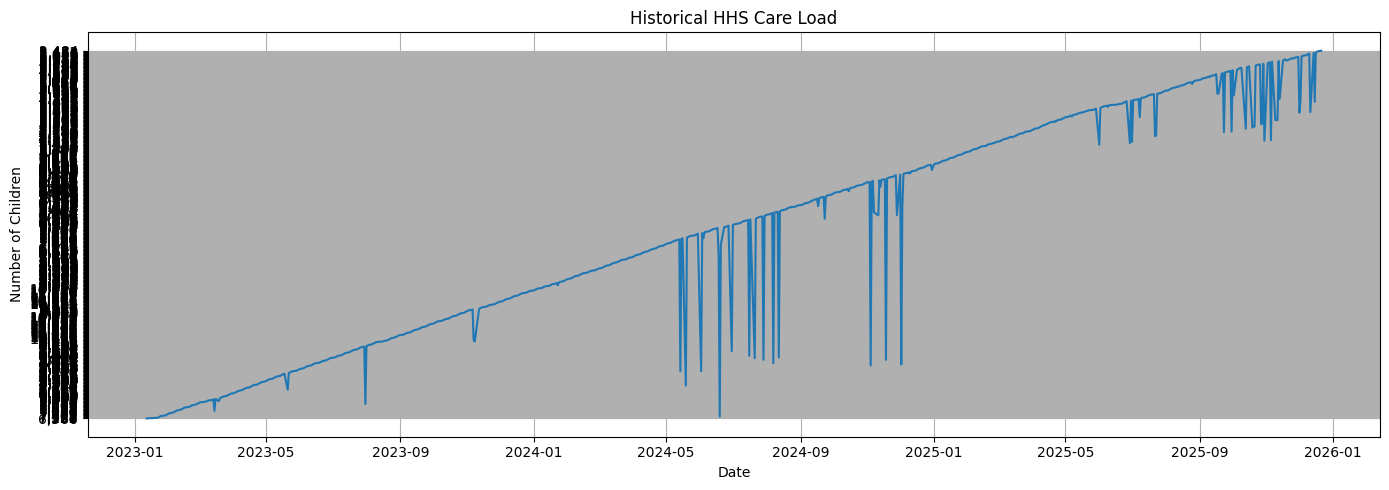

In [16]:
target = "Children in HHS Care"

print(data[target].describe())
print("Missing target values:", data[target].isna().sum())

plt.figure(figsize=(14, 5))
plt.plot(data.index, data[target])
plt.title("Historical HHS Care Load")
plt.xlabel("Date")
plt.ylabel("Number of Children")
plt.grid(True)
plt.tight_layout()
plt.show()


In [17]:
print("Date differences:")
print(data.index.to_series().diff().value_counts().head(10))

full_dates = pd.date_range(
    start=data.index.min(),
    end=data.index.max(),
    freq="D"
)

missing_dates = full_dates.difference(data.index)

print("Missing calendar dates:", len(missing_dates))
print(missing_dates[:10])


Date differences:
Date
1 days     558
3 days     122
4 days      23
2 days      10
5 days       3
10 days      1
6 days       1
7 days       1
Name: count, dtype: int64
Missing calendar dates: 355
DatetimeIndex(['2023-01-13', '2023-01-14', '2023-01-15', '2023-01-16',
               '2023-01-17', '2023-01-18', '2023-01-19', '2023-01-20',
               '2023-01-21', '2023-01-26'],
              dtype='datetime64[ns]', freq=None)


Rows in source after duplicate-date handling: 720
Calendar days: 1075
Missing target values on daily calendar: 355
Original observed target values: 720
Date range: 2023-01-12 00:00:00 to 2025-12-21 00:00:00


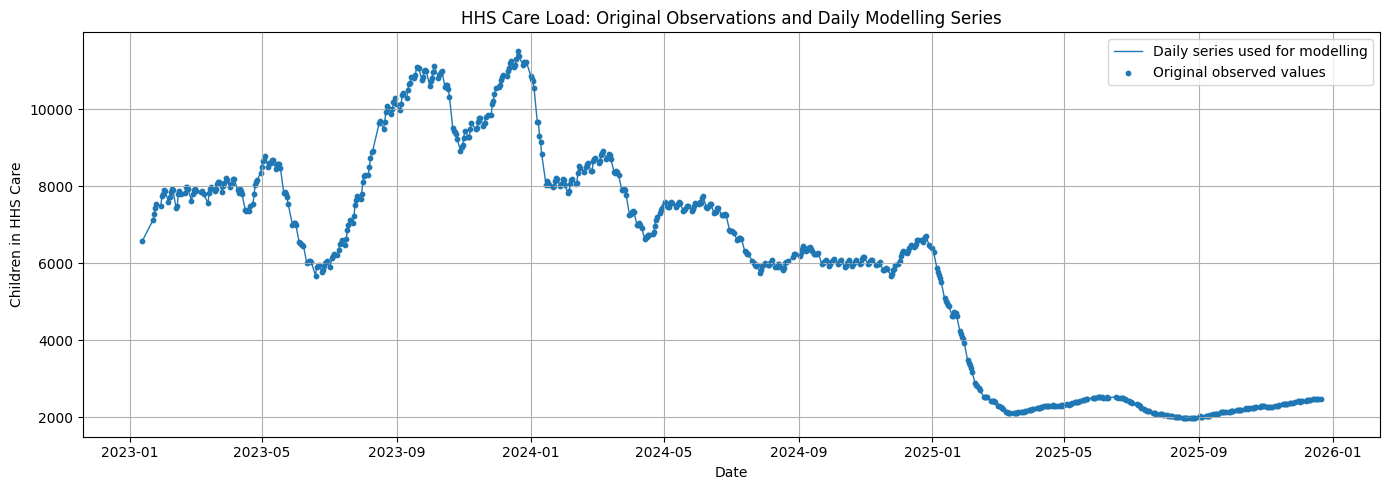

In [18]:
target = "Children in HHS Care"

for col in data.columns:
    data[col] = pd.to_numeric(
        data[col].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    )

data = data.groupby(level=0).mean(numeric_only=True).sort_index()

observed_target = data[target].copy()
daily_target = observed_target.asfreq("D")
observed_mask = daily_target.notna()

print("Rows in source after duplicate-date handling:", len(data))
print("Calendar days:", len(daily_target))
print("Missing target values on daily calendar:", int(daily_target.isna().sum()))
print("Original observed target values:", int(observed_mask.sum()))
print("Date range:", daily_target.index.min(), "to", daily_target.index.max())

daily_target_filled = daily_target.interpolate(method="time").ffill().bfill()
plt.figure(figsize=(14, 5))
plt.plot(daily_target_filled.index, daily_target_filled, label="Daily series used for modelling", linewidth=1)
plt.scatter(observed_target.dropna().index, observed_target.dropna().values, s=10, label="Original observed values")
plt.title("HHS Care Load: Original Observations and Daily Modelling Series")
plt.xlabel("Date")
plt.ylabel("Children in HHS Care")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


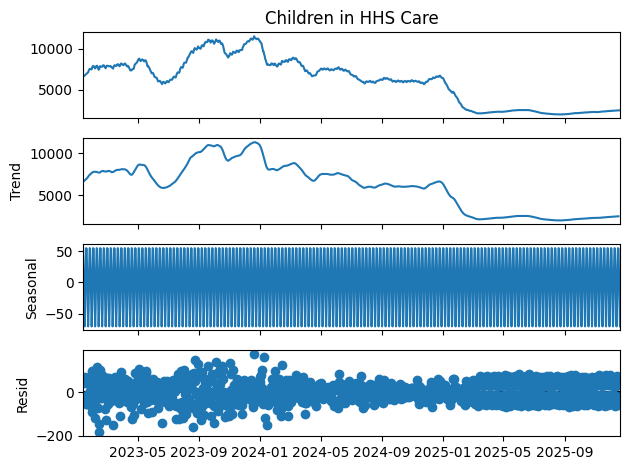

In [19]:
from statsmodels.tsa.seasonal import seasonal_decompose

if len(daily_target_filled) >= 14:
    decomposition = seasonal_decompose(daily_target_filled, model="additive", period=7)
    decomposition.plot()
    plt.tight_layout()
    plt.show()
else:
    print("Not enough daily observations for a 7-day decomposition.")


In [20]:
split_point = int(len(daily_target) * 0.80)
train_raw = daily_target.iloc[:split_point].copy()
test_calendar = daily_target.iloc[split_point:].copy()

train_daily = train_raw.interpolate(method="time").ffill().bfill()
test_actual = test_calendar.dropna()
forecast_steps = len(test_calendar)

print("Training calendar days:", len(train_daily))
print("Test calendar days:", len(test_calendar))
print("Original observed test dates scored:", len(test_actual))
print("Training period:", train_daily.index.min(), "to", train_daily.index.max())
print("Testing period:", test_calendar.index.min(), "to", test_calendar.index.max())

if len(test_actual) == 0:
    raise ValueError("No original observed HHS Care values are available in the test period.")


Training calendar days: 860
Test calendar days: 215
Original observed test dates scored: 140
Training period: 2023-01-12 00:00:00 to 2025-05-20 00:00:00
Testing period: 2025-05-21 00:00:00 to 2025-12-21 00:00:00


In [21]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

naive_forecast = pd.Series(train_daily.iloc[-1], index=test_calendar.index, name="Naive Forecast")

moving_forecast = pd.Series(train_daily.tail(7).mean(), index=test_calendar.index, name="7-Day Moving Average")

es_fit = ExponentialSmoothing(
    train_daily, trend="add", seasonal="add", seasonal_periods=7,
    initialization_method="estimated"
).fit(optimized=True)
es_forecast = pd.Series(es_fit.forecast(forecast_steps).to_numpy(), index=test_calendar.index, name="Exponential Smoothing")

arima_fit = ARIMA(train_daily, order=(1, 1, 1)).fit()
arima_forecast = pd.Series(arima_fit.forecast(steps=forecast_steps).to_numpy(), index=test_calendar.index, name="ARIMA")

sarima_fit = SARIMAX(
    train_daily, order=(1, 1, 1), seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False, enforce_invertibility=False
).fit(disp=False, maxiter=100)
sarima_forecast = pd.Series(sarima_fit.forecast(steps=forecast_steps).to_numpy(), index=test_calendar.index, name="SARIMA")

print("Baseline and statistical forecasts generated.")


Baseline and statistical forecasts generated.


In [22]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

def make_features(history_values, dates):
    """Create features for each date using only values from earlier dates."""
    rows = []
    vals = list(history_values)
    for date in dates:
        rows.append({
            "Lag_1": vals[-1],
            "Lag_7": vals[-7] if len(vals) >= 7 else vals[0],
            "Lag_14": vals[-14] if len(vals) >= 14 else vals[0],
            "Mean_7": float(np.mean(vals[-7:])),
            "Mean_14": float(np.mean(vals[-14:])),
            "DayOfWeek": date.dayofweek,
            "Month": date.month,
            "IsWeekend": int(date.dayofweek >= 5)
        })

    return pd.DataFrame(rows, index=dates)


feature_rows = []
for i in range(14, len(train_daily)):
    hist = train_daily.iloc[:i]
    dt = train_daily.index[i]
    feature_rows.append({
        "Lag_1": hist.iloc[-1], "Lag_7": hist.iloc[-7], "Lag_14": hist.iloc[-14],
        "Mean_7": hist.iloc[-7:].mean(), "Mean_14": hist.iloc[-14:].mean(),
        "DayOfWeek": dt.dayofweek, "Month": dt.month, "IsWeekend": int(dt.dayofweek >= 5)
    })
X_train = pd.DataFrame(feature_rows, index=train_daily.index[14:])
y_train_ml = train_daily.iloc[14:]

rf_model = RandomForestRegressor(n_estimators=300, random_state=42, min_samples_leaf=2)
gb_model = GradientBoostingRegressor(random_state=42, n_estimators=150, learning_rate=0.03, max_depth=2)
rf_model.fit(X_train, y_train_ml)
gb_model.fit(X_train, y_train_ml)

def recursive_ml_forecast(model, history, future_dates):
    history_values = list(np.asarray(history, dtype=float))
    predictions = []
    for dt in future_dates:
        row = pd.DataFrame([{
            "Lag_1": history_values[-1],
            "Lag_7": history_values[-7] if len(history_values) >= 7 else history_values[0],
            "Lag_14": history_values[-14] if len(history_values) >= 14 else history_values[0],
            "Mean_7": float(np.mean(history_values[-7:])),
            "Mean_14": float(np.mean(history_values[-14:])),
            "DayOfWeek": dt.dayofweek,
            "Month": dt.month,
            "IsWeekend": int(dt.dayofweek >= 5)
        }])
        pred = max(0.0, float(model.predict(row)[0]))
        predictions.append(pred)
        history_values.append(pred)
    return pd.Series(predictions, index=future_dates)

rf_forecast = recursive_ml_forecast(rf_model, train_daily, test_calendar.index).rename("Random Forest")
gb_forecast = recursive_ml_forecast(gb_model, train_daily, test_calendar.index).rename("Gradient Boosting")
print("Random Forest and Gradient Boosting forecasts generated.")


Random Forest and Gradient Boosting forecasts generated.


In [63]:
comparison.to_csv("care_load_model_comparison.csv", index=False)

In [23]:
forecasts = {
    "Naive Forecast": naive_forecast,
    "7-Day Moving Average": moving_forecast,
    "Exponential Smoothing": es_forecast,
    "ARIMA": arima_forecast,
    "SARIMA": sarima_forecast,
    "Random Forest": rf_forecast,
    "Gradient Boosting": gb_forecast
}

results = []
for model_name, forecast in forecasts.items():
    aligned = pd.concat([test_actual.rename("actual"), forecast.rename("predicted")], axis=1).dropna()
    nonzero = aligned[aligned["actual"] != 0]
    mape = (np.abs((nonzero["actual"] - nonzero["predicted"]) / nonzero["actual"]).mean() * 100) if len(nonzero) else np.nan
    results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(aligned["actual"], aligned["predicted"]),
        "RMSE": np.sqrt(mean_squared_error(aligned["actual"], aligned["predicted"])),
        "MAPE_%": mape,
        "Scored observations": len(aligned)
    })

comparison = pd.DataFrame(results).sort_values("MAE").reset_index(drop=True)
print(comparison.round(2))


                   Model      MAE     RMSE  MAPE_%  Scored observations
0   7-Day Moving Average   208.51   254.29    9.84                  140
1          Random Forest   217.83   266.03   10.29                  140
2                  ARIMA   223.54   272.74   10.56                  140
3         Naive Forecast   225.72   275.32   10.67                  140
4      Gradient Boosting   258.81   311.22   12.21                  140
5                 SARIMA   405.50   573.23   17.51                  140
6  Exponential Smoothing  2039.29  2265.26   91.83                  140


In [65]:
walk_forward_results.to_csv("walk_forward_validation.csv", index=False)

In [24]:
import numpy as np
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

history = train_daily.squeeze().astype(float).copy()
actual_series = daily_target.squeeze().astype(float)

walk_model = SARIMAX(
    history,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False, maxiter=100)

actual_values = []
naive_values = []
sarima_values = []

for date in test_calendar.index:

    actual = actual_series.loc[date]

    naive_pred = float(history.iloc[-1])
    sarima_pred = float(walk_model.forecast(steps=1).iloc[0])

    if pd.notna(actual):
        actual_values.append(float(actual))
        naive_values.append(naive_pred)
        sarima_values.append(sarima_pred)

    observation = pd.Series(
        [actual],
        index=pd.DatetimeIndex([date]),
        name=history.name
    )

    walk_model = walk_model.append(observation, refit=False)

    next_value = float(actual) if pd.notna(actual) else sarima_pred
    history = pd.concat([
        history,
        pd.Series([next_value], index=[date], name=history.name)
    ])

walk_forward_results = pd.DataFrame({
    "Model": ["Naive Forecast", "SARIMA"],
    "MAE": [
        mean_absolute_error(actual_values, naive_values),
        mean_absolute_error(actual_values, sarima_values)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(actual_values, naive_values)),
        np.sqrt(mean_squared_error(sarima_values, actual_values))
    ]
})

print("Walk-forward validation results:")
print(walk_forward_results.round(2))
print("Observed test days evaluated:", len(actual_values))


Walk-forward validation results:
            Model    MAE   RMSE
0  Naive Forecast   9.99  14.03
1          SARIMA  10.48  15.20
Observed test days evaluated: 140


In [67]:
horizon_results.to_csv("multi_horizon_evaluation.csv", index=False)

In [25]:
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

series = daily_target.squeeze().astype(float).sort_index()

horizons = [1, 7, 14, 30]
max_horizon = max(horizons)

split_point = len(train_daily)

origins = list(range(split_point, len(series) - max_horizon + 1, 30))

results = []

for horizon in horizons:
    actual_values = []
    predicted_values = []

    for origin in origins:
        train_series = series.iloc[:origin]

        model = SARIMAX(
            train_series,
            order=(1, 1, 1),
            seasonal_order=(1, 1, 1, 7),
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        fitted_model = model.fit(disp=False, maxiter=100)

        forecast = fitted_model.forecast(steps=horizon)

        actual = series.iloc[origin + horizon - 1]
        predicted = forecast.iloc[horizon - 1]

        if pd.notna(actual) and pd.notna(predicted):
            actual_values.append(float(actual))
            predicted_values.append(float(predicted))

    if actual_values:
        mae_value = mean_absolute_error(actual_values, predicted_values)
        rmse_value = np.sqrt(mean_squared_error(actual_values, predicted_values))
    else:
        mae_value = np.nan
        rmse_value = np.nan
    results.append({
        "Horizon_Days": horizon,
        "MAE": mae_value,
        "RMSE": rmse_value,
        "Forecast_Count": len(actual_values)
    })

horizon_results = pd.DataFrame(results)

print("Multi-Horizon Evaluation Results:")
print(horizon_results.round(2))


Multi-Horizon Evaluation Results:
   Horizon_Days    MAE    RMSE  Forecast_Count
0             1   9.20   13.19               4
1             7  13.42   15.02               5
2            14  34.13   44.67               4
3            30  81.57  123.09               5


Latest historical date: 2025-12-21 00:00:00
Forecast period: 2025-12-22 to 2026-01-20


,Forecast_HHS_Care,Lower_95,Upper_95
Date,,,
2025-12-22,2485.45,2380.86,2590.04
2025-12-23,2486.36,2315.58,2657.14
2025-12-24,2489.08,2253.38,2724.77
2025-12-25,2487.10,2186.29,2787.91
2025-12-26,2491.19,2118.94,2863.45
2025-12-27,2532.81,772.50,4293.12
2025-12-28,2499.67,2001.79,2997.54
2025-12-29,2500.74,1926.27,3075.21
2025-12-30,2502.22,1850.53,3153.91


Saved: hhs_care_forecast_30_days.csv


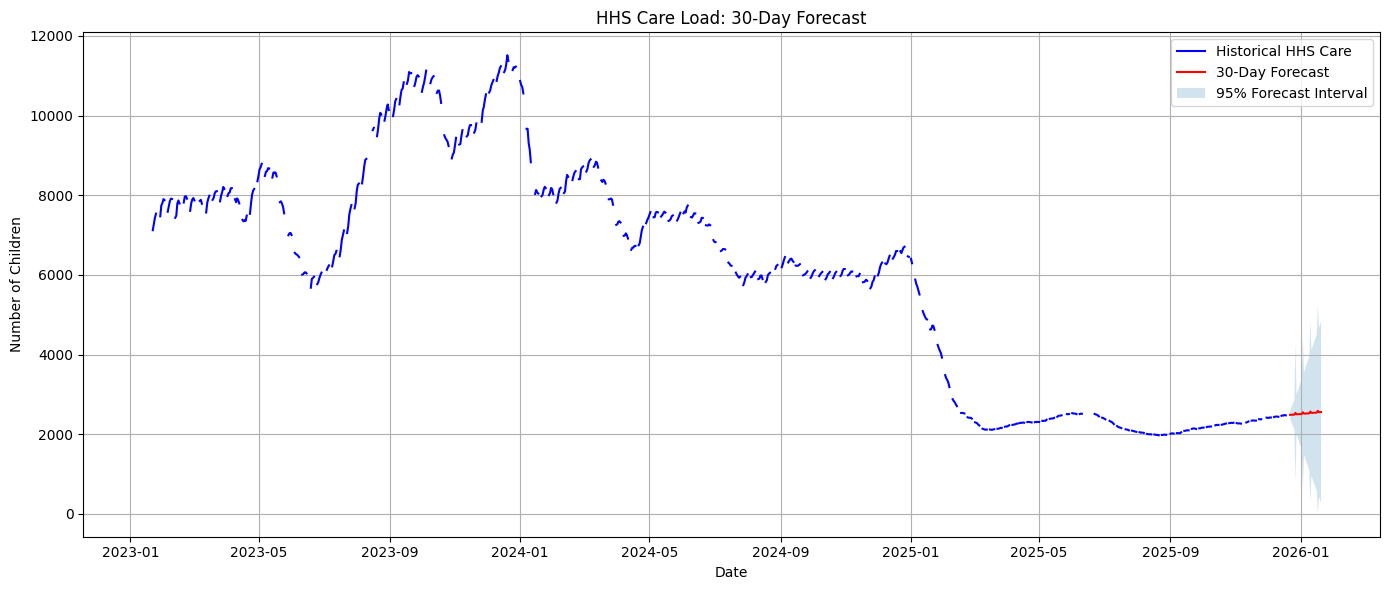

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX

series = daily_target.squeeze().astype(float).sort_index()

series = series.asfreq("D")

if series.notna().sum() < 60:
    raise ValueError("Insufficient observed data for this forecast.")

final_model = SARIMAX(
    series,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

final_fitted_model = final_model.fit(disp=False, maxiter=200)

forecast_result = final_fitted_model.get_forecast(steps=30)

predicted_mean = forecast_result.predicted_mean
confidence_interval = forecast_result.conf_int(alpha=0.05)

future_dates = pd.date_range(
    start=series.index[-1] + pd.Timedelta(days=1),
    periods=30,
    freq="D"
)

care_forecast = pd.DataFrame({
    "Forecast_HHS_Care": np.maximum(predicted_mean.to_numpy(), 0),
    "Lower_95": np.maximum(
        confidence_interval.iloc[:, 0].to_numpy(), 0
    ),
    "Upper_95": np.maximum(
        confidence_interval.iloc[:, 1].to_numpy(), 0
    )
}, index=future_dates)

care_forecast.index.name = "Date"

print("Latest historical date:", series.index[-1])
print("Forecast period:", future_dates[0].date(), "to",
      future_dates[-1].date())
display(care_forecast.round(2))

care_forecast.to_csv("hhs_care_forecast_30_days.csv")
print("Saved: hhs_care_forecast_30_days.csv")

plt.figure(figsize=(14, 6))

plt.plot(
    series.index, series,
    label="Historical HHS Care",
    color="blue"
)

plt.plot(
    care_forecast.index,
    care_forecast["Forecast_HHS_Care"],
    label="30-Day Forecast",
    color="red"
)

plt.fill_between(
    care_forecast.index,
    care_forecast["Lower_95"],
    care_forecast["Upper_95"],
    alpha=0.2,
    label="95% Forecast Interval"
)

plt.title("HHS Care Load: 30-Day Forecast")
plt.xlabel("Date")
plt.ylabel("Number of Children")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


,Forecast_Discharges,Lower_95,Upper_95
Date,,,
2025-12-22,13.22,0.0,68.71
2025-12-23,13.17,0.0,74.67
2025-12-24,13.90,0.0,78.19
2025-12-25,15.46,0.0,81.58
2025-12-26,47.23,0.0,135.93
2025-12-27,61.45,0.0,1880.85
2025-12-28,10.30,0.0,81.40
2025-12-29,12.36,0.0,86.77
2025-12-30,13.15,0.0,89.68


Saved: hhs_discharge_forecast_30_days.csv


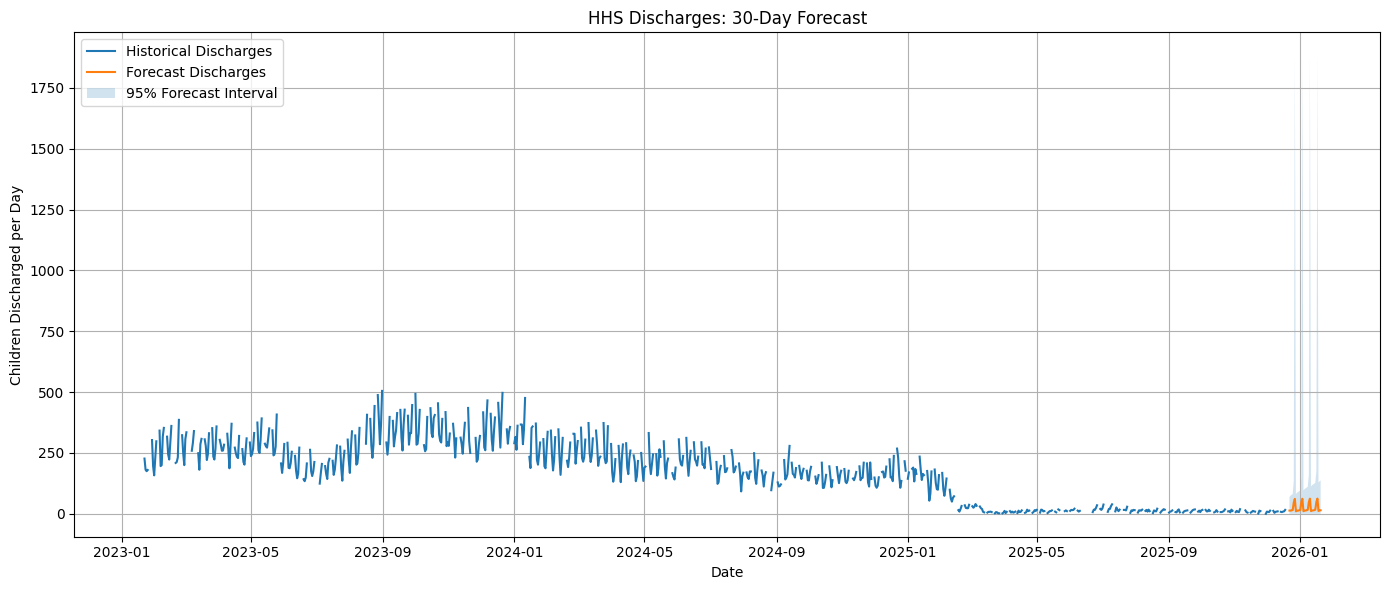

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX

discharge_target = "Children discharged from HHS Care"

discharge_series = (
    data[discharge_target]
    .astype(float)
    .sort_index()
    .asfreq("D")
)

if discharge_series.notna().sum() < 60:
    raise ValueError("Insufficient observed discharge data.")

discharge_model = SARIMAX(
    discharge_series,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

discharge_fitted = discharge_model.fit(
    disp=False,
    maxiter=200
)

discharge_result = discharge_fitted.get_forecast(steps=30)
discharge_interval = discharge_result.conf_int(alpha=0.05)

future_dates = pd.date_range(
    start=discharge_series.index[-1] + pd.Timedelta(days=1),
    periods=30,
    freq="D"
)

discharge_forecast = pd.DataFrame({
    "Forecast_Discharges": np.maximum(
        discharge_result.predicted_mean.to_numpy(), 0
    ),
    "Lower_95": np.maximum(
        discharge_interval.iloc[:, 0].to_numpy(), 0
    ),
    "Upper_95": np.maximum(
        discharge_interval.iloc[:, 1].to_numpy(), 0
    )
}, index=future_dates)

discharge_forecast.index.name = "Date"

display(discharge_forecast.round(2))

discharge_forecast.to_csv(
    "hhs_discharge_forecast_30_days.csv"
)

print("Saved: hhs_discharge_forecast_30_days.csv")

plt.figure(figsize=(14, 6))

plt.plot(
    discharge_series.index,
    discharge_series,
    label="Historical Discharges"
)

plt.plot(
    discharge_forecast.index,
    discharge_forecast["Forecast_Discharges"],
    label="Forecast Discharges"
)

plt.fill_between(
    discharge_forecast.index,
    discharge_forecast["Lower_95"],
    discharge_forecast["Upper_95"],
    alpha=0.2,
    label="95% Forecast Interval"
)

plt.title("HHS Discharges: 30-Day Forecast")
plt.xlabel("Date")
plt.ylabel("Children Discharged per Day")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


,Forecast_HHS_Care,Lower_95,Upper_95,Capacity_Utilization_Pct,Capacity_Gap,Forecast_Exceeds_Capacity,Estimated_Excess,Risk_Level
Date,,,,,,,,
2025-12-22,2485.45,2380.86,2590.04,155.34,-885.45,True,885.45,Capacity Threshold Reached
2025-12-23,2486.36,2315.58,2657.14,155.40,-886.36,True,886.36,Capacity Threshold Reached
2025-12-24,2489.08,2253.38,2724.77,155.57,-889.08,True,889.08,Capacity Threshold Reached
2025-12-25,2487.10,2186.29,2787.91,155.44,-887.10,True,887.10,Capacity Threshold Reached
2025-12-26,2491.19,2118.94,2863.45,155.70,-891.19,True,891.19,Capacity Threshold Reached
2025-12-27,2532.81,772.50,4293.12,158.30,-932.81,True,932.81,Capacity Threshold Reached
2025-12-28,2499.67,2001.79,2997.54,156.23,-899.67,True,899.67,Capacity Threshold Reached
2025-12-29,2500.74,1926.27,3075.21,156.30,-900.74,True,900.74,Capacity Threshold Reached
2025-12-30,2502.22,1850.53,3153.91,156.39,-902.22,True,902.22,Capacity Threshold Reached


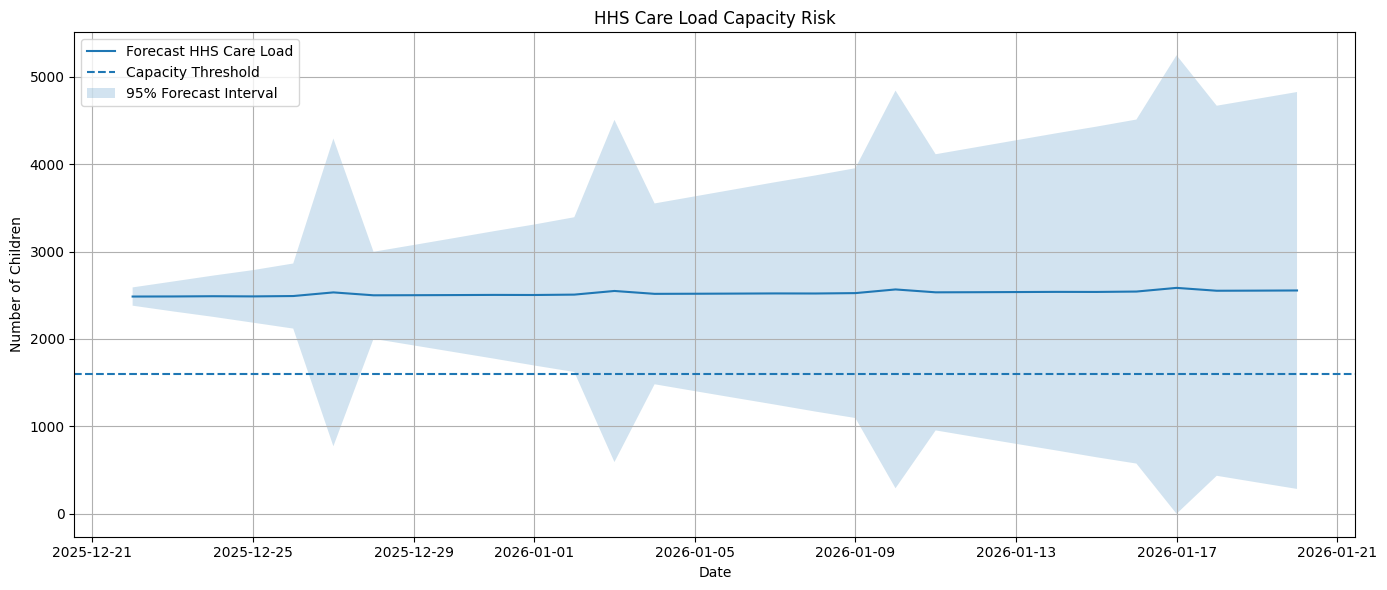

In [59]:
capacity_threshold = 1600

if capacity_threshold is None:
    print("Capacity-risk analysis not calculated.")
else:
    risk_analysis = care_forecast[["Forecast_HHS_Care", "Lower_95", "Upper_95"]].copy()
    risk_analysis["Capacity_Utilization_Pct"] = risk_analysis["Forecast_HHS_Care"] / float(capacity_threshold) * 100
    risk_analysis["Capacity_Gap"] = float(capacity_threshold) - risk_analysis["Forecast_HHS_Care"]
    risk_analysis["Forecast_Exceeds_Capacity"] = risk_analysis["Forecast_HHS_Care"] >= float(capacity_threshold)
    risk_analysis["Estimated_Excess"] = np.maximum(0, risk_analysis["Forecast_HHS_Care"] - float(capacity_threshold))
    risk_analysis["Risk_Level"] = np.select(
        [risk_analysis["Forecast_Exceeds_Capacity"], risk_analysis["Capacity_Utilization_Pct"] >= 90, risk_analysis["Capacity_Utilization_Pct"] >= 80],
        ["Capacity Threshold Reached", "High Risk", "Moderate Risk"],
        default="Normal"
    )
    display(risk_analysis.round(2))
    risk_analysis.to_csv("hhs_capacity_risk_30_days.csv")
    plt.figure(figsize=(14, 6))
    plt.plot(risk_analysis.index, risk_analysis["Forecast_HHS_Care"], label="Forecast HHS Care Load")
    plt.axhline(float(capacity_threshold), linestyle="--", label="Capacity Threshold")
    plt.fill_between(risk_analysis.index, risk_analysis["Lower_95"], risk_analysis["Upper_95"], alpha=0.2, label="95% Forecast Interval")
    plt.title("HHS Care Load Capacity Risk")
    plt.xlabel("Date")
    plt.ylabel("Number of Children")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


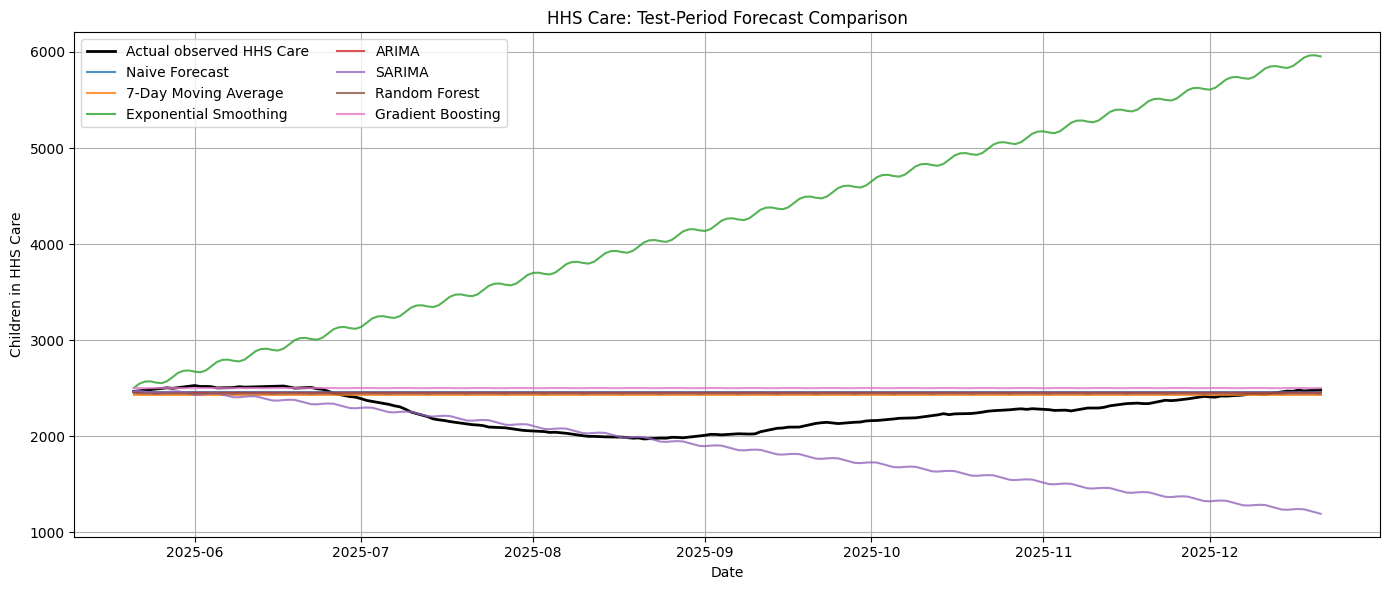

In [29]:
plt.figure(figsize=(14, 6))
plt.plot(test_actual.index, test_actual.values, label="Actual observed HHS Care", linewidth=2, color="black")
for model_name, forecast in forecasts.items():
    plt.plot(forecast.index, forecast.values, label=model_name, alpha=0.8)
plt.title("HHS Care: Test-Period Forecast Comparison")
plt.xlabel("Date")
plt.ylabel("Children in HHS Care")
plt.legend(ncol=2)
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
comparison.to_csv("care_load_model_comparison.csv", index=False)